# Что мы знаем о данных

Здесь собраны наблюдения о данных, на которых построено решение, и что из них следует для решения. Колонки, пропуски и странные значения разобраны в `ingestion/raw.ipynb`, а здесь — графики и выводы из них.

**Что есть в данных.**

- **Корпус** — файл `benchmark_items.parquet`, 189 212 объявлений, почти все из категории «Услуги» (раздел 4). Это все объявления, среди которых мы ищем: ответ на любой тестовый запрос — 50 объявлений из корпуса.
- **Тестовые запросы** — файл `benchmark_queries.parquet`, 2 452 запроса. Какие объявления по ним выбрали пользователи, нам не дают.
- **Train** — файл `train.parquet`, 497 673 строки. Каждая строка — один выбор пользователя: поля поиска (текст, локация, фильтры, категория, флаг доставки) и объявление, которое он выбрал. Номера запроса у строк нет, поэтому **запросом** мы называем весь набор полей поиска: строки train с одинаковыми полями склеиваются в один запрос. Выбранные в train объявления в основном не входят в корпус. Все объявления — и из корпуса, и те, что встречаются только в train, — лежат у нас в одной таблице, а колонка `in_corpus` показывает, входит ли объявление в корпус.

**Как оценивается ответ.** Правильные объявления запроса — те, которые пользователь действительно выбрал. **Recall@50** — доля правильных объявлений запроса, попавших в наши 50 ответов, усреднённая по запросам. Для тестовых запросов его считают только организаторы, а результат виден на лидерборде — таблице результатов конкурса. У себя качество проверяем на **валидации**: это 5 032 запроса из train, для которых ответ известен (как они отобраны — `validation/split.ipynb`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from avito.ingestion import load
from avito.ranking.features import haversine_km
from avito.retrieval.location import fit_search_centroids

pl.Config.set_tbl_cols(-1)
pl.Config.set_tbl_rows(20)
pl.Config.set_fmt_str_lengths(80)
pl.Config.set_tbl_width_chars(200);
plt.rcParams["figure.figsize"] = (9, 4);

Загружаем train, тестовые запросы и таблицу всех объявлений и проверяем размеры. Отдельно считаем, сколько объявлений встречается только в train и в какой доле строк train выбранное объявление лежит в корпусе.

In [2]:
train = load.load_train()
bench = load.load_bench_queries()
items = load.load_items(["item_id", "in_corpus", "item_category_id", "item_location_id", "item_latitude", "item_longitude"])
corpus = items.filter(pl.col("in_corpus"))

pl.DataFrame({
    "показатель": [
        "строк в train",
        "тестовых запросов",
        "объявлений в корпусе",
        "объявлений, которые встречаются только в train",
        "доля строк train, где выбранное объявление лежит в корпусе",
    ],
    "значение": [
        float(train.height),
        float(bench.height),
        float(corpus.height),
        float(items.height - corpus.height),
        train.join(corpus.select("item_id"), on="item_id", how="semi").height / train.height,
    ],
})

показатель,значение
str,f64
"""строк в train""",497673.0
"""тестовых запросов""",2452.0
"""объявлений в корпусе""",189212.0
"""объявлений, которые встречаются только в train""",326683.0
"""доля строк train, где выбранное объявление лежит в корпусе""",0.066329


Объявление из корпуса выбрано только в 6.6% строк train, остальные выборы приходятся на объявления вне корпуса. Значит, train в основном рассказывает, как люди выбирают (в каких местах, какие категории), а не какие именно объявления корпуса правильные. Поэтому ниже поведение пользователей смотрим по всем выбранным объявлениям, а не только по корпусу.

## 1. Одни запросы очень частые, большинство — редкие

Считаем, сколько раз каждый текст запроса встречается в train, и сортируем тексты от частых к редким. Левый график — сколько раз встречается текст в зависимости от его места в этом списке (обе оси в логарифмическом масштабе). Правый график — какая доля всех строк train приходится на самые частые тексты.

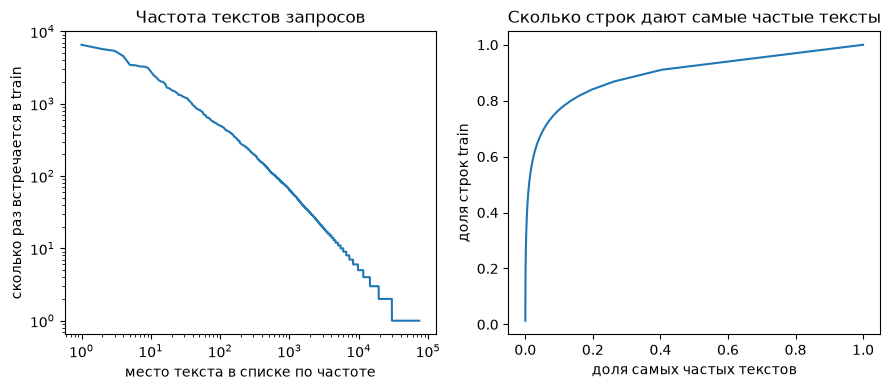

In [3]:
text_counts = train.group_by("search_query").len("rows").sort("rows", descending=True)
cumulative = text_counts["rows"].cum_sum() / train.height

fig, axes = plt.subplots(1, 2)
axes[0].loglog(np.arange(1, text_counts.height + 1), text_counts["rows"].to_numpy())
axes[0].set_xlabel("место текста в списке по частоте")
axes[0].set_ylabel("сколько раз встречается в train")
axes[0].set_title("Частота текстов запросов")
axes[1].plot(np.arange(1, text_counts.height + 1) / text_counts.height, cumulative.to_numpy())
axes[1].set_xlabel("доля самых частых текстов")
axes[1].set_ylabel("доля строк train")
axes[1].set_title("Сколько строк дают самые частые тексты")
plt.tight_layout()
plt.show()

Десять самых частых текстов запросов в train:

In [4]:
text_counts.head(10).rename({"search_query": "текст запроса", "rows": "сколько строк в train"})

текст запроса,сколько строк в train
str,u32
"""маникюр""",6540
"""массаж""",5702
"""наращивание ресниц""",5395
"""установка кондиционеров""",4573
"""педикюр""",3436
"""сантехник""",3405
"""вывоз мусора""",3278
"""эвакуатор""",3263
"""электрик""",3158


Те же наблюдения в цифрах. Заодно сравниваем с тестовыми запросами: сколько среди них разных текстов, какая доля их текстов уже встречалась в train и сколько из 100 самых частых текстов train есть в тесте.

In [5]:
pl.DataFrame({
    "показатель": [
        "разных текстов запросов в train",
        "текстов, которые встречаются в train 1 000 раз и чаще",
        "доля текстов, которые встречаются в train один раз",
        "какая доля строк train приходится на 100 самых частых текстов",
        "какая доля строк train приходится на 1% самых частых текстов",
        "разных текстов среди 2 452 тестовых запросов",
        "доля тестовых запросов, текст которых встречается в train",
        "сколько из 100 самых частых текстов train есть среди тестовых запросов",
    ],
    "значение": [
        float(text_counts.height),
        float((text_counts["rows"] >= 1000).sum()),
        (text_counts["rows"] == 1).mean(),
        text_counts.head(100)["rows"].sum() / train.height,
        text_counts.head(text_counts.height // 100)["rows"].sum() / train.height,
        float(bench["search_query"].n_unique()),
        bench.join(text_counts, on="search_query", how="semi").height / bench.height,
        float(text_counts.head(100).join(bench, on="search_query", how="semi").height),
    ],
})

показатель,значение
str,f64
"""разных текстов запросов в train""",74529.0
"""текстов, которые встречаются в train 1 000 раз и чаще""",39.0
"""доля текстов, которые встречаются в train один раз""",0.59821
"""какая доля строк train приходится на 100 самых частых текстов""",0.250866
"""какая доля строк train приходится на 1% самых частых текстов""",0.487947
"""разных текстов среди 2 452 тестовых запросов""",2452.0
"""доля тестовых запросов, текст которых встречается в train""",0.369902
"""сколько из 100 самых частых текстов train есть среди тестовых запросов""",1.0


Самые частые тексты — «маникюр» (6 540 строк), «массаж» (5 702) и «наращивание ресниц» (5 395), а всего 39 текстов встречаются тысячу раз и чаще. На 100 самых частых текстов приходится четверть строк train, на 1% самых частых — почти половина, а 60% текстов встречаются всего один раз.

В тестовых запросах картина другая: все 2 452 текста разные, так что любой текст, даже самый частый в train, встречается в тесте не больше одного раза. Из 100 самых частых текстов train в тест попал только один. 37% тестовых текстов уже встречались в train, а 63% — новые, так что для большинства тестовых запросов нельзя просто взять то, что выбирали по этому тексту в train.

Поэтому в валидации мы делаем так же, как в тесте, и берём каждый текст запроса один раз. Иначе валидация в основном показывала бы, как решение справляется с «маникюром» и другими частыми текстами, а не с такими запросами, как в тесте (подробнее — `validation/split.ipynb`).

## 2. Услугу выбирают там же, где ищут

У каждого запроса есть `search_location_id` — где пользователь искал, у каждого объявления есть `item_location_id` — где оказывают услугу. Оба — номера локаций из одного справочника: города, посёлки, регионы. Названий локаций в данных нет, только номера.

Объявление привязано к конкретному месту, а искать можно шире: по целому региону или по всей стране (что такие локации поиска есть, видно ниже по координатам выбранных объявлений). Поэтому делим локации поиска на два вида:

- **поиск по городу** — есть хотя бы одно объявление (из корпуса или только из train) с той же локацией, что у запроса; городом для краткости называем любой населённый пункт;
- **поиск по региону или стране** — ни у одного объявления такой локации нет.

Для каждой строки train проверяем, лежит ли выбранное объявление в той же локации, где искали.

In [6]:
city_locations = items.select(pl.col("item_location_id").alias("search_location_id")).unique()
city_locations = city_locations.with_columns(pl.lit("поиск по городу").alias("вид поиска"))

rows = train.join(items.select("item_id", "item_location_id", "item_latitude", "item_longitude"), on="item_id")
rows = rows.join(city_locations, on="search_location_id", how="left")
rows = rows.with_columns(
    pl.col("вид поиска").fill_null("поиск по региону или стране"),
    (pl.col("item_location_id") == pl.col("search_location_id")).alias("same_location"),
)

by_kind = rows.group_by("вид поиска").agg(
    pl.col("search_location_id").n_unique().alias("разных локаций поиска"),
    pl.len().alias("строк train"),
    pl.col("same_location").mean().alias("доля выбранных в той же локации"),
).sort("вид поиска")
overall = rows.select(
    pl.lit("все запросы").alias("вид поиска"),
    pl.col("search_location_id").n_unique().alias("разных локаций поиска"),
    pl.len().alias("строк train"),
    pl.col("same_location").mean().alias("доля выбранных в той же локации"),
)

pl.concat([by_kind, overall])

вид поиска,разных локаций поиска,строк train,доля выбранных в той же локации
str,u32,u32,f64
"""поиск по городу""",2483,443931,0.931622
"""поиск по региону или стране""",299,53742,0.0
"""все запросы""",2782,497673,0.83102


В 83% случаев выбранное объявление лежит в той же локации, где искали, а при поиске по городу — в 93%. При поиске по региону совпадения быть не может по определению: у объявлений таких локаций нет, поэтому там 0.

Где тогда лежат остальные выбранные объявления? Смотрим на расстояние. Для каждой локации поиска берём её центр — медиану координат (отдельно широты и долготы) всех объявлений, которые выбирали при поиске в этой локации; для города это практически центр города. Каждое выбранное объявление относим к одной из групп: в той же локации; в другой локации, но не дальше 50 км от центра; 50–300 км; дальше 300 км; и отдельно — объявления без координат.

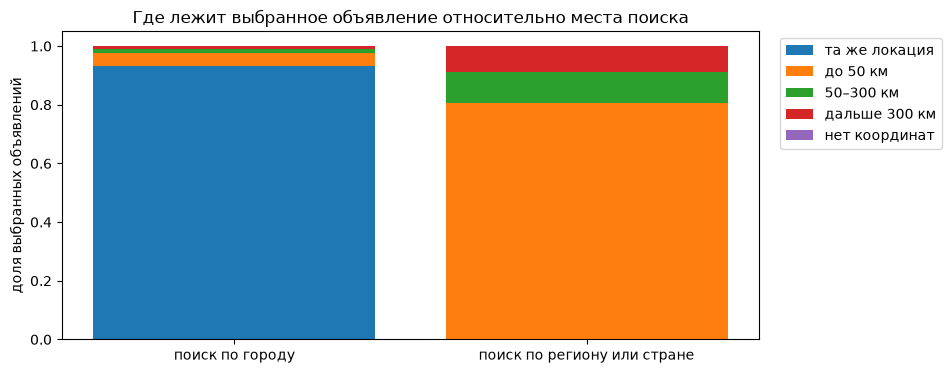

вид поиска,та же локация,до 50 км,50–300 км,дальше 300 км,нет координат
str,f64,f64,f64,f64,f64
"""поиск по региону или стране""",0.0,0.807395,0.103364,0.088962,0.000279
"""поиск по городу""",0.931622,0.043595,0.016244,0.008526,0.000014


In [7]:
centroids = fit_search_centroids(rows)
rows = rows.join(centroids, on="search_location_id", how="left")
rows = rows.with_columns(
    haversine_km(pl.col("search_latitude"), pl.col("search_longitude"), pl.col("item_latitude"), pl.col("item_longitude")).alias("distance_km")
)
rows = rows.with_columns(
    pl.when(pl.col("same_location")).then(pl.lit("та же локация"))
    .when(pl.col("distance_km").is_null()).then(pl.lit("нет координат"))
    .when(pl.col("distance_km") <= 50).then(pl.lit("до 50 км"))
    .when(pl.col("distance_km") <= 300).then(pl.lit("50–300 км"))
    .otherwise(pl.lit("дальше 300 км"))
    .alias("where")
)

places = ["та же локация", "до 50 км", "50–300 км", "дальше 300 км", "нет координат"]
kinds = ["поиск по городу", "поиск по региону или стране"]
shares = rows.group_by("вид поиска", "where").len("rows")
shares = shares.with_columns((pl.col("rows") / pl.col("rows").sum().over("вид поиска")).alias("share"))

bottom = np.zeros(len(kinds))
for place in places:
    values = np.array([shares.filter((pl.col("вид поиска") == kind) & (pl.col("where") == place))["share"].sum() for kind in kinds])
    plt.bar(kinds, values, bottom=bottom, label=place)
    bottom += values
plt.ylabel("доля выбранных объявлений")
plt.title("Где лежит выбранное объявление относительно места поиска")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

shares.pivot(on="where", index="вид поиска", values="share").select(["вид поиска"] + places).fill_null(0.0)

При поиске по городу 93% выбранных объявлений лежат в самом городе и ещё 4% — в другой локации не дальше 50 км от центра, то есть в пригородах. При поиске по региону 81% выбранных объявлений лежат не дальше 50 км от центра. Центр здесь — не географический центр области, а медиана выбранных объявлений, то есть практически главный город региона. Объявлений без координат в обоих видах поиска меньше 0.1%.

Разберём поиск по региону подробнее. Названий локаций нет, поэтому узнаём их по координатам выбранных объявлений. Для пяти самых частых широких локаций поиска считаем медианные координаты выбранных объявлений, число разных локаций у выбранных, самую частую из них и её долю среди выборов, а также долю выбранных дальше 300 км от центра.

In [8]:
region_rows = rows.filter(pl.col("вид поиска") == "поиск по региону или стране")
region_rows.group_by("search_location_id").agg(
    pl.len().alias("строк train"),
    pl.col("item_latitude").median().alias("медианная широта"),
    pl.col("item_longitude").median().alias("медианная долгота"),
    pl.col("item_location_id").n_unique().alias("разных локаций выбранных"),
    pl.col("item_location_id").mode().first().alias("самая частая локация выбранных"),
    (pl.col("item_location_id") == pl.col("item_location_id").mode().first()).mean().alias("её доля среди выборов"),
    (pl.col("distance_km") > 300).mean().alias("доля дальше 300 км"),
).sort("строк train", descending=True).head(5)

search_location_id,строк train,медианная широта,медианная долгота,разных локаций выбранных,самая частая локация выбранных,её доля среди выборов,доля дальше 300 км
i64,u32,f64,f64,u32,i64,f64,f64
107620,12277,55.750935,37.617698,233,637640,0.612283,0.009369
621540,6839,55.752522,37.781339,590,637640,0.273432,0.610038
107621,6310,59.93362,30.338863,138,653240,0.794929,0.012048
637680,1528,55.733135,37.726358,169,637770,0.055628,0.009823
632660,1422,45.039625,38.99707,108,633540,0.654008,0.017593


Пять самых частых широких локаций поиска:

- `107620` — медианная точка выбранных объявлений 55.75° с. ш., 37.62° в. д., это Москва; 61% выборов приходится на одну локацию `637640`, а дальше 300 км почти ничего нет. Это поиск по «Москве и области».
- `621540` — выбирают в сотнях разных локаций, и больше половины выбранных объявлений лежат дальше 300 км от центра. Это поиск по всей России. Медианные координаты попадают в Москву просто потому, что на Москву (`637640`) приходится самая большая доля выборов — 27%.
- `107621` — медианная точка 59.93° с. ш., 30.34° в. д., это Петербург; почти 80% выборов приходится на одну локацию. Это «Санкт-Петербург и область».
- `637680` — медианная точка тоже около Москвы, но самая частая локация выбранных — не Москва, и на неё приходится только 6% выборов: выбирают по многим городам вокруг Москвы. Вероятно, это поиск по Московской области без самой Москвы.
- `632660` — медианная точка 45.04° с. ш., 38.99° в. д., это Краснодар; 65% выборов приходится на одну локацию. Вероятно, это поиск по Краснодарскому краю.

Посмотрим, где лежат объявления, выбранные при поиске по `107620`. Для каждой локации выбранного объявления считаем, сколько объявлений в ней выбрали, их медианное расстояние до центра и долю от всех выбранных при этом поиске; показываем десять самых частых локаций.

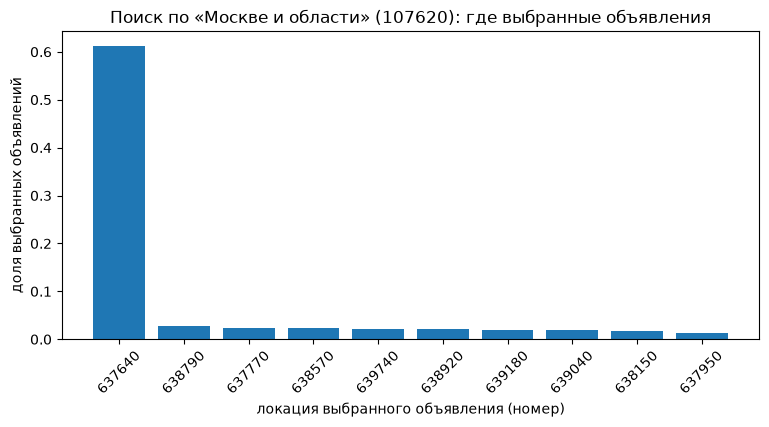

item_location_id,выбрано объявлений,"медианное расстояние до центра, км",доля от всех выбранных при поиске по 107620
i64,u32,f64,f64
637640,7517,10.242026,0.612283
638790,346,19.134662,0.028183
637770,300,21.002349,0.024436
638570,295,20.180767,0.024029
639740,261,19.040034,0.021259
638920,256,19.226689,0.020852
639180,237,35.852205,0.019304
639040,226,23.568977,0.018408
638150,210,36.144136,0.017105


In [9]:
moscow_region = rows.filter(pl.col("search_location_id") == 107620)
spread = moscow_region.group_by("item_location_id").agg(
    pl.len().alias("выбрано объявлений"),
    pl.col("distance_km").median().alias("медианное расстояние до центра, км"),
).sort("выбрано объявлений", descending=True)
spread = spread.with_columns((pl.col("выбрано объявлений") / moscow_region.height).alias("доля от всех выбранных при поиске по 107620"))

top = spread.head(10)
plt.bar([str(location) for location in top["item_location_id"].to_list()], top["доля от всех выбранных при поиске по 107620"].to_list())
plt.xticks(rotation=45)
plt.xlabel("локация выбранного объявления (номер)")
plt.ylabel("доля выбранных объявлений")
plt.title("Поиск по «Москве и области» (107620): где выбранные объявления")
plt.show()

top

61% выбранных объявлений лежат в локации `637640`: медианное расстояние до центра — 10 км, это сама Москва. Остальные 39% разбросаны ещё по 232 локациям (всего у выбранных 233 разные локации, см. таблицу выше); самые частые из них (девять следующих строк таблицы) лежат в 19–36 км от центра, то есть это города Московской области.

**Что это даёт решению.** Локация сильно подсказывает ответ: 83% выбранных объявлений лежат там, где искали, а в `retrieval/baseline.ipynb` учёт локации поднимает Recall@50 поиска по словам с 0.47 до 0.87. Но просто оставлять объявления из локации поиска нельзя: при поиске по региону таких объявлений нет вовсе, а при поиске по городу часть людей выбирает пригороды.

Поэтому считаем по train **доли выборов по локациям**: для каждой локации поиска — какая доля выборов при поиске в ней пришлась на каждую локацию объявления. Для «Москвы и области» это 61% на саму Москву и остальное на города области. В решении доли считаются не по всему train, а по его части в 482 161 строку, из которой убраны проверочные запросы и запросы для обучения реранкера — модели LightGBM, которая заново упорядочивает найденные объявления и берёт первые 50 (как делится train — `validation/split.ipynb`). Доли служат подсказкой: чем чаще при таком поиске выбирали объявления из данной локации, тем выше объявление в нашем списке ответов. Как именно доли складываются с оценкой по тексту — в `retrieval/baseline.ipynb`.

## 3. Сколько объявлений в каждой локации

Считаем, сколько объявлений корпуса лежит в каждой локации, и рисуем, сколько локаций приходится на каждое число объявлений. Заодно проверяем тестовые запросы: у какой доли из них в локации поиска нет ни одного объявления корпуса, что это за запросы и встречается ли локация поиска тестового запроса в train (иначе для него не будет долей выборов).

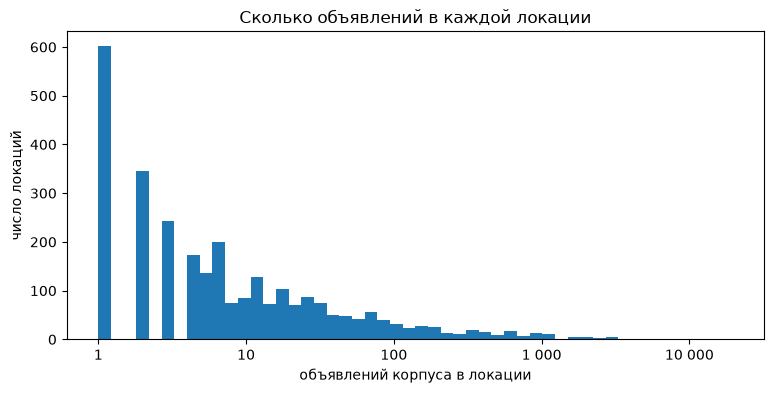

показатель,значение
str,f64
"""локаций, в которых есть объявления корпуса""",2877.0
"""медианное число объявлений корпуса в локации""",5.0
"""объявлений корпуса в самой большой локации""",19543.0
"""доля тестовых запросов без объявлений корпуса в локации поиска""",0.174144
"""из них — поиски по региону или стране (по определению из раздела 2)""",0.995316
"""доля тестовых запросов, локация поиска которых встречается в train""",1.0


In [10]:
corpus_per_location = corpus.group_by("item_location_id").len("items")

plt.hist(np.log10(corpus_per_location["items"].to_numpy()), bins=50)
plt.xticks([0, 1, 2, 3, 4], ["1", "10", "100", "1 000", "10 000"])
plt.xlabel("объявлений корпуса в локации")
plt.ylabel("число локаций")
plt.title("Сколько объявлений в каждой локации")
plt.show()

corpus_locations = corpus.select(pl.col("item_location_id").alias("search_location_id")).unique()
bench_without_corpus = bench.join(corpus_locations, on="search_location_id", how="anti")
pl.DataFrame({
    "показатель": [
        "локаций, в которых есть объявления корпуса",
        "медианное число объявлений корпуса в локации",
        "объявлений корпуса в самой большой локации",
        "доля тестовых запросов без объявлений корпуса в локации поиска",
        "из них — поиски по региону или стране (по определению из раздела 2)",
        "доля тестовых запросов, локация поиска которых встречается в train",
    ],
    "значение": [
        float(corpus_per_location.height),
        corpus_per_location["items"].median(),
        float(corpus_per_location["items"].max()),
        bench_without_corpus.height / bench.height,
        bench_without_corpus.join(city_locations, on="search_location_id", how="anti").height / bench_without_corpus.height,
        bench.join(train.select("search_location_id").unique(), on="search_location_id", how="semi").height / bench.height,
    ],
})

Пять локаций с наибольшим числом объявлений корпуса. Названий нет, поэтому рядом — медианные координаты их объявлений: по ним видно, какой это город.

In [11]:
corpus.group_by("item_location_id").agg(
    pl.len().alias("объявлений корпуса"),
    pl.col("item_latitude").median().alias("медианная широта"),
    pl.col("item_longitude").median().alias("медианная долгота"),
).sort("объявлений корпуса", descending=True).head(5)

item_location_id,объявлений корпуса,медианная широта,медианная долгота
i64,u32,f64,f64
637640,19543,55.755863,37.617698
653240,12145,59.938669,30.321734
633540,4494,45.044081,38.98983
650400,3659,55.796127,49.12466
641780,3178,55.030204,82.920433


Объявления распределены по локациям очень неравномерно. Больше всего их в Москве (`637640`, 19 543 объявления) и Петербурге (`653240`, 12 145), дальше идут Краснодар, Казань и Новосибирск — от 3.2 до 4.5 тысячи. А у половины локаций корпуса не больше пяти объявлений.

Одной локации для ответа мало: в Москве почти 20 тысяч объявлений, а вернуть нужно 50. Главный отбор делает поиск по тексту, а локация помогает поднять выше объявления из тех мест, где при таком поиске обычно выбирают.

У 17% тестовых запросов в локации поиска нет ни одного объявления корпуса, и почти все они (99.5%) — поиски по региону или стране; остальные — населённые пункты, где объявления есть только в train. Этим запросам особенно нужны доли выборов по локациям: они показывают, в каких городах выбирают при таком поиске. Локация поиска каждого тестового запроса встречается в train, так что посчитать по train доли выборов можно для всех тестовых запросов.

## 4. Выбирают услуги

Корпус почти целиком состоит из объявлений категории «Услуги» (`item_category_id = 114`). Проверяем, объявления каких категорий выбирают в train (по всем выбранным объявлениям, а не только из корпуса) и сколько в корпусе объявлений других категорий.

In [12]:
chosen = train.join(items.select("item_id", "item_category_id"), on="item_id")
not_services = corpus.filter(pl.col("item_category_id") != 114)

pl.DataFrame({
    "показатель": [
        "доля выбранных в train объявлений из категории «Услуги»",
        "доля объявлений корпуса из категории «Услуги»",
        "объявлений корпуса не из «Услуг»",
        "разных категорий среди них",
    ],
    "значение": [
        (chosen["item_category_id"] == 114).mean(),
        (corpus["item_category_id"] == 114).mean(),
        float(not_services.height),
        float(not_services["item_category_id"].n_unique()),
    ],
})

показатель,значение
str,f64
"""доля выбранных в train объявлений из категории «Услуги»""",0.99997
"""доля объявлений корпуса из категории «Услуги»""",0.990085
"""объявлений корпуса не из «Услуг»""",1876.0
"""разных категорий среди них""",46.0


Что это за объявления не из «Услуг». Названий категорий в данных нет, поэтому для 15 самых больших категорий показываем число объявлений в корпусе и заголовок первого объявления категории.

In [13]:
titles = load.load_corpus(["item_id", "item_title_raw"])
not_services.join(titles, on="item_id").group_by("item_category_id").agg(
    pl.len().alias("объявлений корпуса"),
    pl.col("item_title_raw").first().alias("пример заголовка"),
).sort(["объявлений корпуса", "item_category_id"], descending=[True, False]).head(15)

item_category_id,объявлений корпуса,пример заголовка
i64,u32,str
19,357,"""Срубы для бань"""
112,141,"""Художник по костюмам (дизайнер, модельер, бутафор)"""
40,122,"""Оборудование магазина под ключ"""
33,103,"""Тур на полуостров Рыбачий"""
10,98,"""Запчасти на Мерседес Спринтер CDI 311"""
20,84,"""Офисный Стол с Брифом Lati"""
25,82,"""Дом 434,4 м² на участке 10 сот."""
36,74,"""Объемные стикеры на телефон для бизнеса оптом"""
111,74,"""Строительство вахта"""


Выбирают практически только услуги: 99.997% выбранных в train объявлений. В корпусе услуг 99%, остальной 1% — 1 876 объявлений из 46 других категорий. Судя по примерам заголовков, среди них есть товары (срубы для бань, запчасти, мебель, настольные игры), вакансии («Художник по костюмам», «Строительство вахта»), туры и недвижимость (дома, квартиры).

Значит, судя по train, объявления не из «Услуг» почти никогда не бывают правильным ответом. Мы их из корпуса не удаляем и отдельно не обрабатываем: это всего 1% корпуса. Признак «из «Услуг» ли объявление» пробовали в реранкере вместе с другими свойствами объявления, но в итоговую модель он не вошёл (`ranking/ranker.ipynb`).

## 5. Поиск по всему Авито

Отдельная особенность теста: часть запросов ищет не в категории «Услуги», а по всему Авито (`search_category = 0`). Считаем, сколько таких строк в train и таких запросов в тесте.

In [14]:
pl.DataFrame({
    "где": ["строки train", "тестовые запросы"],
    "с search_category = 0": [(train["search_category"] == 0).sum(), (bench["search_category"] == 0).sum()],
    "доля": [(train["search_category"] == 0).mean(), (bench["search_category"] == 0).mean()],
})

где,с search_category = 0,доля
str,i64,f64
"""строки train""",34,0.000068
"""тестовые запросы""",222,0.090538


В тесте таких запросов 9%, а в train — всего 34 строки из полумиллиона. Поэтому в валидации таких запросов почти нет, и проверить качество на них у себя нельзя. Вероятно, это одна из причин, почему на лидерборде результат ниже, чем на валидации (Recall@50 0.922 против 0.950, см. `README.md`), но проверить это мы не можем.

Единственная подсказка — что выбирали в этих 34 строках train. Считаем, сколько из них пришлось на объявления из «Услуг»:

In [15]:
category_zero = train.filter(pl.col("search_category") == 0).join(items.select("item_id", "item_category_id"), on="item_id")

pl.DataFrame({
    "показатель": ["строк train с search_category = 0", "из них выбрано объявление из «Услуг»"],
    "значение": [category_zero.height, (category_zero["item_category_id"] == 114).sum()],
})

показатель,значение
str,i64
"""строк train с search_category = 0""",34
"""из них выбрано объявление из «Услуг»""",34


Во всех 34 строках выбрали объявление из «Услуг». Для уверенных выводов это слишком мало, но других данных нет. Поэтому запросы по всему Авито обрабатываем так же, как остальные, и объявления не из «Услуг» для них отдельно не поднимаем; как это сказывается на тестовых запросах, мы не проверяли.

## Выводы

- **Частые и редкие запросы.** В train самые частые тексты вроде «маникюра» повторяются тысячи раз, а 60% текстов встречаются один раз. В тесте все тексты разные, и 63% из них в train не встречались. Поэтому и в валидации мы берём каждый текст один раз.
- **Локация сильно подсказывает ответ.** 83% выбранных объявлений лежат там же, где искали; при поиске по городу — 93% и ещё 4% в пригородах. При поиске по региону 81% выбранных объявлений лежат не дальше 50 км от центра региона, то есть практически от его главного города. Поэтому вместо жёсткого фильтра по локации используем доли выборов по локациям, посчитанные по train; локация поиска каждого тестового запроса в train встречается.
- **Объявления распределены по локациям очень неравномерно:** от единиц до почти 20 тысяч в Москве. Одной локации мало, главный отбор делает поиск по тексту. У 17% тестовых запросов в локации поиска нет ни одного объявления корпуса, и почти все это поиски по региону или стране.
- **Выбирают практически только услуги** (99.997% выбранных в train). 1% объявлений корпуса не из «Услуг» мы не удаляем и отдельно не обрабатываем.
- **9% тестовых запросов ищут по всему Авито**, а в train таких всего 34 строки, и во всех выбирали услуги. Проверить качество на таких запросах нельзя, поэтому обрабатываем их так же, как остальные.